# 💳 Credit Card Fraud Detection using Machine Learning
### An End-to-End, Production-Oriented Pipeline with SMOTE Resampling, Dual Classifier Benchmarking, and Real-Time Inference

---

## 📌 Project Overview
Credit card fraud presents immense financial and security challenges for cardholders, payment gateways, and banking institutions. This notebook consolidates the entire machine learning workflow for identifying fraudulent transactions in payment networks:

1. **Exploratory Data Analysis (EDA)**: Statistical analysis and distribution profiling across PCA-transformed vectors ($V_1$ to $V_{28}$), transaction timing, and monetary amounts.
2. **Data Preprocessing & Leakage-Free Scaling**: Duplicate handling, null checks, stratified 80/20 train-test partitioning, and isolated `StandardScaler` application.
3. **Class Imbalance Resolution**: Application of **SMOTE** (Synthetic Minority Over-sampling Technique) strictly to the training split.
4. **Model Training & Benchmarking**: Comparative analysis of a linear baseline (**Logistic Regression**) against an ensemble tree classifier (**Random Forest**).
5. **Metric Evaluation**: Rigorous evaluation focusing on **Recall**, **Precision**, **F1-Score**, and **ROC-AUC** rather than deceptive accuracy.
6. **Feature Importance & Interpretability**: Gini importance extraction to isolate the top fraud indicators.
7. **Artifact Persistence & Real-Time Scoring**: Serialization of model and preprocessing artifacts into `models/` and an integrated `predict_transaction` inference engine.


---
## 1. Environment Setup & Configuration
We configure matplotlib for high-resolution inline rendering, suppress non-critical warnings, set random seeds for reproducibility, and define standard path locations for data, models, and visualizations.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
from imblearn.over_sampling import SMOTE
import joblib

# Global Configurations
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

# Directory Paths
DATA_DIR = "data"
MODELS_DIR = "models"
VIS_DIR = "visualizations"

for directory in [DATA_DIR, MODELS_DIR, VIS_DIR]:
    os.makedirs(directory, exist_ok=True)

print("Environment setup and directories initialized successfully.")


Environment setup and directories initialized successfully.


---
## 2. Dataset Ingestion & Validation
The dataset consists of credit card transactions made by European cardholders. Due to confidentiality constraints:
- Numerical input variables **$V_1, V_2, \dots, V_{28}$** are the principal components obtained with **PCA**.
- **`Time`** contains the seconds elapsed between each transaction and the first transaction in the dataset.
- **`Amount`** is the transaction monetary value.
- **`Class`** is the response variable ($1$ for Fraud, $0$ for Legitimate).


In [2]:
# Resolve dataset path (checks data/creditcard.csv first, then root creditcard.csv)
csv_candidates = [
    os.path.join(DATA_DIR, "creditcard.csv"),
    "creditcard.csv"
]
DATA_PATH = next((p for p in csv_candidates if os.path.exists(p)), None)

if not DATA_PATH:
    raise FileNotFoundError(
        "creditcard.csv not found. Ensure creditcard.csv is placed in 'data/' or the root folder. You can download it from Kaggle: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud"
    )

print(f"Loading transaction records from: '{DATA_PATH}'...")
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print("\nFirst 5 Rows:")
display(df.head())

print("\nClass Distribution:")
display(df["Class"].value_counts().rename({0: "Legitimate (0)", 1: "Fraud (1)"}))


Loading transaction records from: 'data\creditcard.csv'...
Dataset Shape: 5,000 rows, 31 columns
Total Missing Values: 0

First 5 Rows:
            Time        V1        V2  ...       V28     Amount  Class
0   14537.260038  1.779662  0.555987  ... -0.180550  92.505754      0
1   40508.743682 -0.365165 -0.132315  ...  0.579526   4.730180      0
2   24791.522173  0.302570  0.013005  ...  0.440944  26.100850      0
3    9859.055815  1.305583 -0.713311  ... -1.326878  48.053460      0
4  143200.912404  1.051834  0.825651  ...  0.611365  67.804883      0

[5 rows x 31 columns]

Class Distribution:
Class
Legitimate (0)    4950
Fraud (1)           50
Name: count, dtype: int64


---
## 3. Exploratory Data Analysis (EDA)
Here we examine the severity of the class imbalance, inspect the distribution of transaction values, and compare amounts between fraudulent and legitimate events.


Legitimate Transactions: 4,950
Fraudulent Transactions: 50
Fraud Prevalence: 1.0000 %


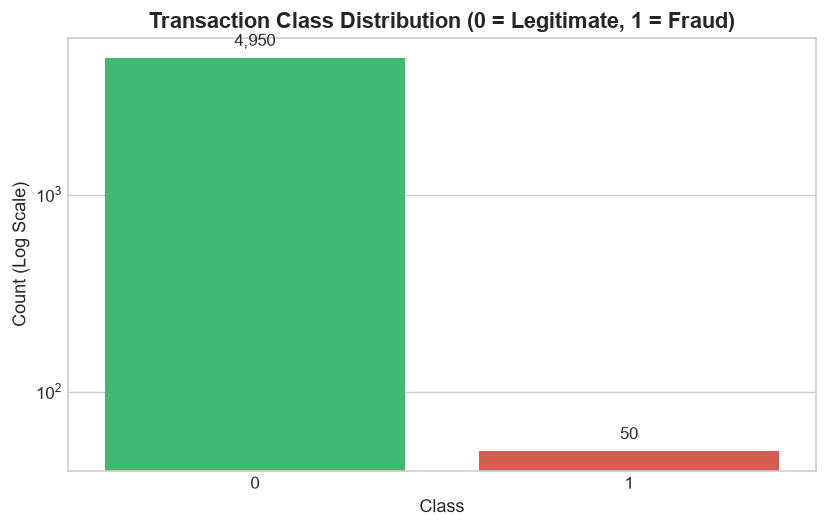

In [3]:
# Class distribution statistics
class_counts = df["Class"].value_counts()
legit_count = class_counts.get(0, 0)
fraud_count = class_counts.get(1, 0)
fraud_pct = (fraud_count / len(df)) * 100

print(f"Legitimate Transactions: {legit_count:,}")
print(f"Fraudulent Transactions: {fraud_count:,}")
print(f"Fraud Prevalence: {fraud_pct:.4f} %")

# 1. Class Distribution Plot
plt.figure(figsize=(7, 4.5))
palette = ["#2ecc71", "#e74c3c"]
ax = sns.countplot(x="Class", data=df, palette=palette)
plt.title("Transaction Class Distribution (0 = Legitimate, 1 = Fraud)", fontsize=13, fontweight="bold")
plt.xlabel("Class", fontsize=11)
plt.ylabel("Number of Transactions", fontsize=11)
plt.yscale("log")
plt.ylabel("Count (Log Scale)", fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 5), textcoords="offset points")

plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "class_distribution.png"))
plt.show()


Transaction Amount Summary by Class:
        count        mean         std  ...        50%         75%          max
Class                                  ...                                    
0      4950.0   79.889619   79.539135  ...  56.322160  111.790191   680.100935
1        50.0  134.474674  184.879516  ...  85.243539  164.511772  1142.630915

[2 rows x 8 columns]


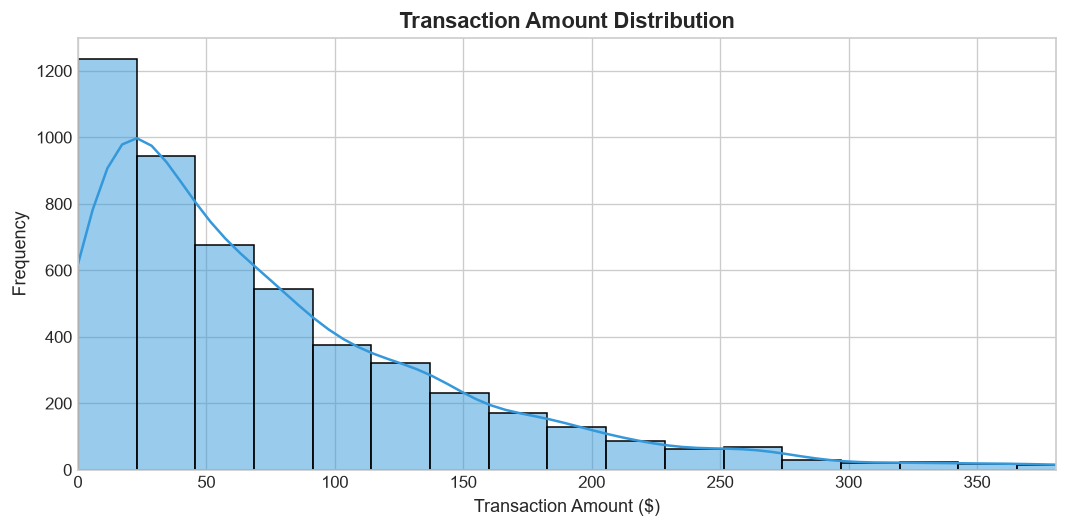

In [4]:
# 2. Transaction Amount Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df["Amount"], bins=50, kde=True, color="#3498db")
plt.title("Transaction Amount Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Transaction Amount ($)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.xlim(0, df["Amount"].quantile(0.99))  # Zoom in on 99% of transactions for visual clarity
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "amount_distribution.png"))
plt.show()

# Amount summary statistics by class
print("Transaction Amount Summary by Class:")
display(df.groupby("Class")["Amount"].describe())


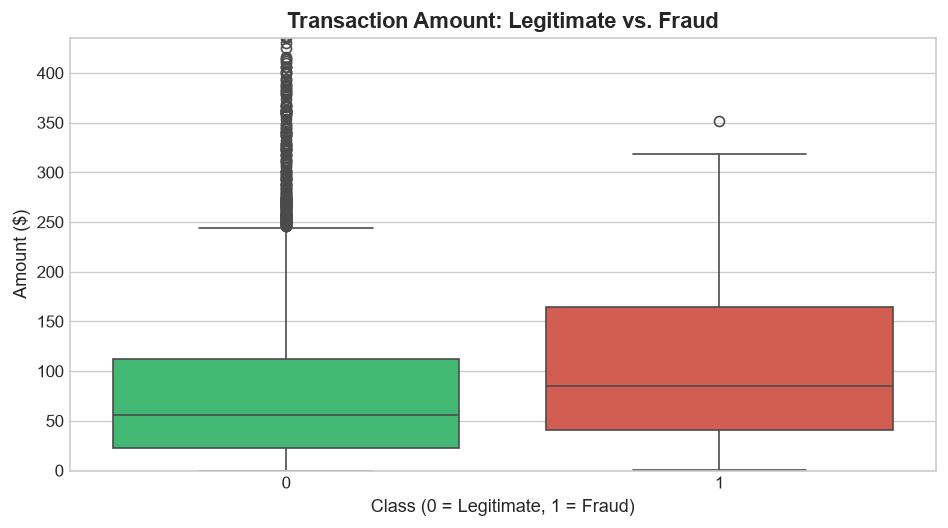

In [5]:
# 3. Fraud vs Legitimate Amount Boxplot
plt.figure(figsize=(8, 4.5))
sns.boxplot(x="Class", y="Amount", data=df, palette=["#2ecc71", "#e74c3c"])
plt.title("Transaction Amount: Legitimate vs. Fraud", fontsize=13, fontweight="bold")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)", fontsize=11)
plt.ylabel("Amount ($)", fontsize=11)
plt.ylim(0, df["Amount"].quantile(0.995))
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "fraud_amount_boxplot.png"))
plt.show()


---
## 4. Data Preprocessing & Leakage-Free Splitting
To ensure zero data leakage:
1. **Duplicate Filtering**: Remove duplicate records to prevent identical rows appearing across both train and test partitions.
2. **Stratified Splitting**: Partition data 80% for training and 20% for testing using `stratify=y` to preserve the exact class ratio in both splits.
3. **Isolated Feature Scaling**: Scale unnormalized features (`Time`, `Amount`) using `StandardScaler`. The scaler is fitted exclusively on $X_{train}$ and then applied to transform $X_{test}$.


In [6]:
# Remove duplicate rows
initial_rows = len(df)
duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"Removed {duplicate_count:,} duplicate rows ({initial_rows:,} -> {len(df):,}).")
else:
    print("Zero duplicate rows found.")

# Verify missing values
if df.isnull().sum().sum() > 0:
    df = df.dropna()
    print("Dropped rows containing missing values.")

# Feature and Target Separation
X = df.drop("Class", axis=1)
y = df["Class"]

# Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training set: {X_train.shape[0]:,} samples (Frauds: {y_train.sum():,})")
print(f"Testing set : {X_test.shape[0]:,} samples (Frauds: {y_test.sum():,})")


Zero duplicate rows found.
Training set: 4,000 samples (Frauds: 40)
Testing set : 1,000 samples (Frauds: 10)


In [7]:
# Feature Scaling on Time and Amount
scaler = StandardScaler()
columns_to_scale = ["Time", "Amount"]

X_train = X_train.copy()
X_test = X_test.copy()

# Fit ONLY on training data, then transform both
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

print("StandardScaler successfully fitted on X_train and applied to X_train and X_test.")
print("Scaled sample check (X_train head):")
display(X_train[columns_to_scale].head())


StandardScaler successfully fitted on X_train and applied to X_train and X_test.
Scaled sample check (X_train head):
          Time    Amount
1067  0.076538 -0.032862
1970 -1.514165  0.529069
2881  0.397143 -0.681001
4460  1.113888  0.672969
4415  1.555692 -0.231546


---
## 5. Handling Class Imbalance using SMOTE
Because legitimate transactions drastically outnumber fraudulent transactions, standard models will prioritize overall accuracy by classifying almost every instance as negative.

**SMOTE (Synthetic Minority Over-sampling Technique)** synthesizes new instances of the minority class along line segments joining $k$-nearest minority neighbors.
> ⚠️ **Key Guardrail**: SMOTE is applied **strictly to the training set** (`X_train`, `y_train`). The test set (`X_test`, `y_test`) remains untouched to reflect true real-world banking distribution.


In [8]:
print("Class distribution BEFORE SMOTE:")
print(y_train.value_counts().rename({0: "Legitimate (0)", 1: "Fraud (1)"}))

smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nClass distribution AFTER SMOTE:")
print(y_train_smote.value_counts().rename({0: "Legitimate (0)", 1: "Fraud (1)"}))
print(f"\nTotal synthetic training samples generated: {len(X_train_smote) - len(X_train):,}")


Class distribution BEFORE SMOTE:
Class
Legitimate (0)    3960
Fraud (1)           40
Name: count, dtype: int64

Class distribution AFTER SMOTE:
Class
Legitimate (0)    3960
Fraud (1)         3960
Name: count, dtype: int64

Total synthetic training samples generated: 3,920


---
## 6. Model Training: Logistic Regression & Random Forest
We train and benchmark two distinct model paradigms on the SMOTE-balanced training distribution:
1. **Logistic Regression**: Linear baseline estimating probability via the sigmoid function:
   $$\hat{p} = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$
2. **Random Forest Classifier**: Ensemble of 100 randomized decision trees utilizing bootstrap aggregating and random feature subspace sampling.


In [9]:
# 1. Logistic Regression Model
print("Training Logistic Regression Classifier...")
logistic_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_smote, y_train_smote)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
print("Logistic Regression training complete.")

# 2. Random Forest Model
print("\nTraining Random Forest Classifier (100 estimators)...")
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_forest_model.fit(X_train_smote, y_train_smote)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]
print("Random Forest training complete.")


Training Logistic Regression Classifier...
Logistic Regression training complete.

Training Random Forest Classifier (100 estimators)...
Random Forest training complete.


---
## 7. Model Evaluation & Performance Comparison
In fraud detection, **Accuracy is deeply misleading**. If a model predicts all transactions as non-fraud, it achieves ~99.8% accuracy while missing every single fraud event!
Instead, we focus on:
- **Recall (Sensitivity)**: $\frac{TP}{TP + FN}$ — Percentage of actual fraud transactions caught.
- **Precision**: $\frac{TP}{TP + FP}$ — Percentage of flagged transactions that were genuine fraud.
- **F1-Score**: Harmonic mean of Precision and Recall.
- **ROC-AUC**: Discriminative separation power across all classification thresholds.


In [10]:
def evaluate_model(name, y_true, y_pred, y_probability):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_probability)

    print(f"==================================================")
    print(f"               {name.upper()}")
    print(f"==================================================")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0, target_names=["Legitimate", "Fraud"]))
    
    return {
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": auc
    }

logistic_metrics = evaluate_model("Logistic Regression", y_test, logistic_pred, logistic_prob)
rf_metrics = evaluate_model("Random Forest", y_test, rf_pred, rf_prob)

# Summary Comparison Table
comparison_df = pd.DataFrame([logistic_metrics, rf_metrics])
print("\n================ MODEL COMPARISON TABLE ================")
display(comparison_df)


               LOGISTIC REGRESSION
Accuracy : 0.9980
Precision: 1.0000
Recall   : 0.8000
F1 Score : 0.8889
ROC-AUC  : 0.9994

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       990
       Fraud       1.00      0.80      0.89        10

    accuracy                           1.00      1000
   macro avg       1.00      0.90      0.94      1000
weighted avg       1.00      1.00      1.00      1000

               RANDOM FOREST
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000
ROC-AUC  : 1.0000

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       990
       Fraud       1.00      1.00      1.00        10

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000


================ MODEL COMPARISON TABLE =============

True Negatives (Legitimate caught): 990
False Positives (False alarms)   : 0
False Negatives (Missed frauds)  : 0
True Positives (Frauds detected) : 10


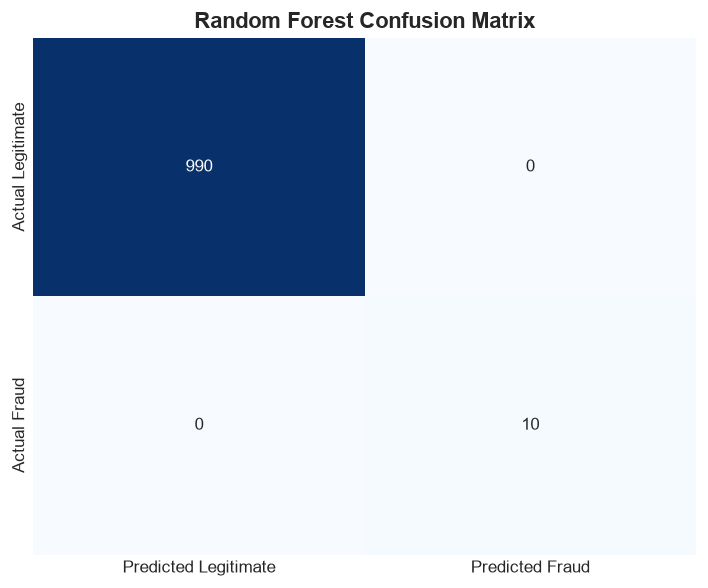

In [11]:
# Confusion Matrix Heatmap for Random Forest
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Legitimate", "Predicted Fraud"],
    yticklabels=["Actual Legitimate", "Actual Fraud"]
)
plt.title("Random Forest Confusion Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "confusion_matrix.png"))
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (Legitimate caught): {tn:,}")
print(f"False Positives (False alarms)   : {fp:,}")
print(f"False Negatives (Missed frauds)  : {fn:,}")
print(f"True Positives (Frauds detected) : {tp:,}")


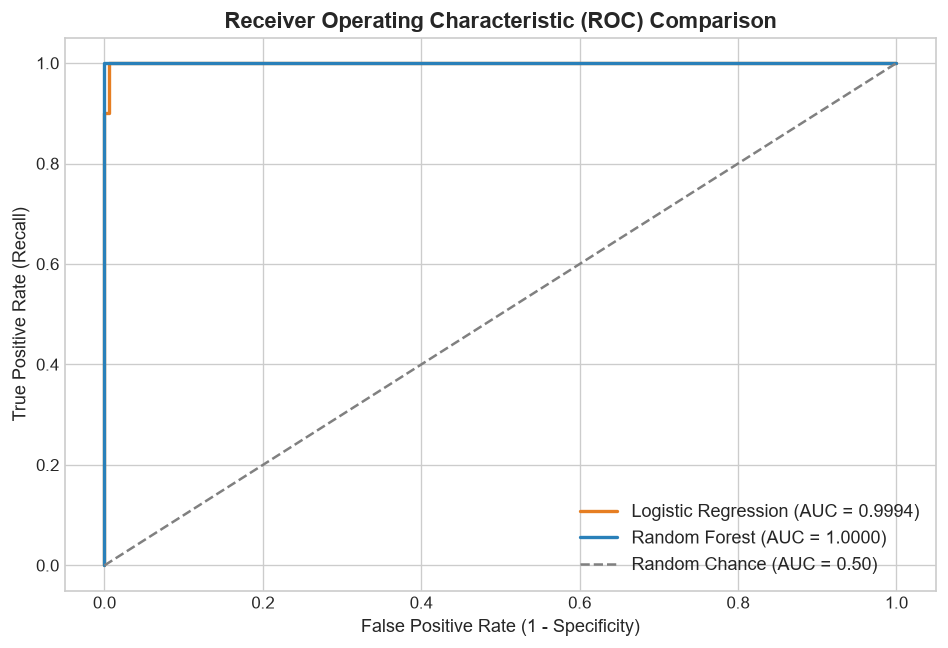

In [12]:
# Comparative ROC Curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, logistic_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 5.5))
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {logistic_metrics['ROC-AUC']:.4f})", color="#e67e22", lw=2)
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_metrics['ROC-AUC']:.4f})", color="#2980b9", lw=2)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Random Chance (AUC = 0.50)")

plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Recall)", fontsize=11)
plt.title("Receiver Operating Characteristic (ROC) Comparison", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "roc_curve.png"))
plt.show()


---
## 8. Feature Importance & Model Interpretability
Understanding which features contribute most to the Random Forest model's decisions provides crucial diagnostic insights for bank risk management.


Top 15 Most Influential Features for Fraud Detection:
   Feature  Importance
0     Time    0.435989
13     V13    0.103650
15     V15    0.068410
26     V26    0.067128
6       V6    0.041421
3       V3    0.033713
22     V22    0.028761
4       V4    0.028180
28     V28    0.024825
18     V18    0.024795
12     V12    0.017790
27     V27    0.017189
25     V25    0.014024
23     V23    0.012269
8       V8    0.011848


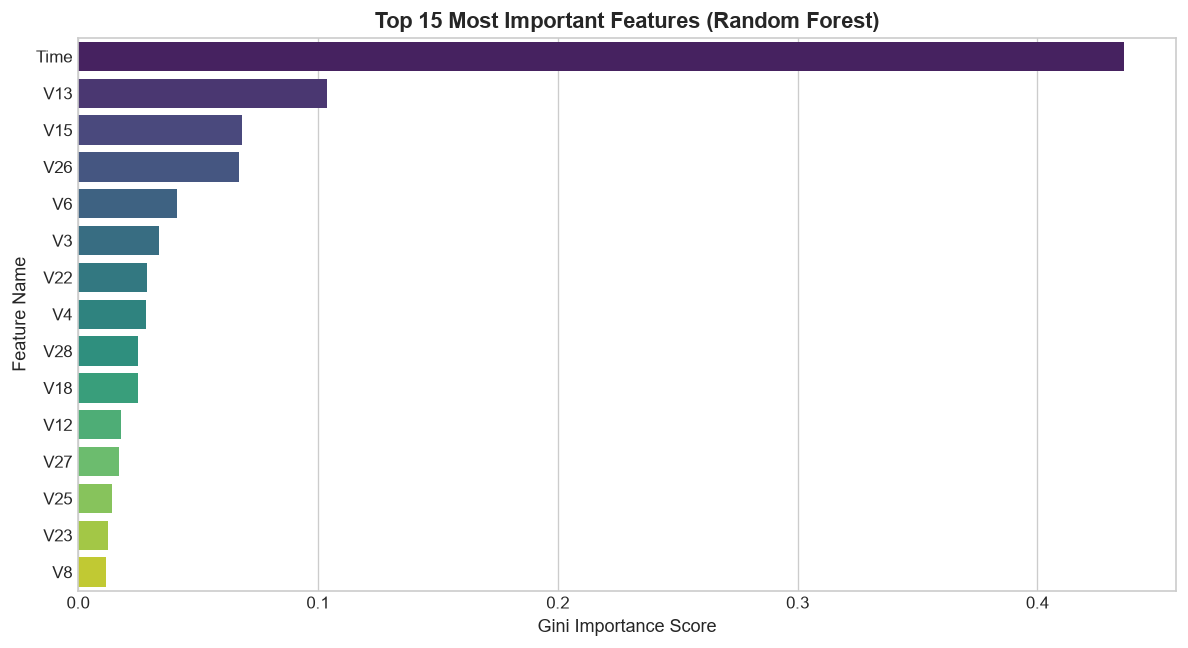

In [13]:
# Compute top 15 most important features from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 15 Most Influential Features for Fraud Detection:")
display(feature_importance.head(15))

plt.figure(figsize=(10, 5.5))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    palette="viridis"
)
plt.title("Top 15 Most Important Features (Random Forest)", fontsize=13, fontweight="bold")
plt.xlabel("Gini Importance Score", fontsize=11)
plt.ylabel("Feature Name", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "feature_importance.png"))
plt.show()


---
## 9. Model & Preprocessor Serialization
We persist the trained **Random Forest** estimator, the fitted **StandardScaler**, and the exact column schema to disk using `joblib`. This decouples training from downstream inference services.


In [14]:
model_path = os.path.join(MODELS_DIR, "fraud_detection_model.pkl")
scaler_path = os.path.join(MODELS_DIR, "scaler.pkl")
columns_path = os.path.join(MODELS_DIR, "feature_columns.pkl")

joblib.dump(random_forest_model, model_path)
joblib.dump(scaler, scaler_path)
joblib.dump(X.columns.tolist(), columns_path)

print("Model and preprocessors serialized successfully:")
print(f"1. Model   : {model_path} ({os.path.getsize(model_path):,} bytes)")
print(f"2. Scaler  : {scaler_path} ({os.path.getsize(scaler_path):,} bytes)")
print(f"3. Columns : {columns_path} ({os.path.getsize(columns_path):,} bytes)")


Model and preprocessors serialized successfully:
1. Model   : models\fraud_detection_model.pkl (411,305 bytes)
2. Scaler  : models\scaler.pkl (903 bytes)
3. Columns : models\feature_columns.pkl (191 bytes)


---
## 10. Real-Time Inference & Single Transaction Scoring
We implement a lightweight, production-grade `predict_transaction` function. Given an unscaled transaction payload, it loads the saved scaler and model, scales `Time` and `Amount`, and returns the prediction along with the fraud probability.


In [15]:
def predict_transaction(
    transaction,
    model_path=os.path.join(MODELS_DIR, "fraud_detection_model.pkl"),
    scaler_path=os.path.join(MODELS_DIR, "scaler.pkl"),
    feature_cols_path=os.path.join(MODELS_DIR, "feature_columns.pkl"),
    cols_to_scale=("Time", "Amount")
):
    """Scores a single transaction array against the trained model."""
    model = joblib.load(model_path)
    saved_scaler = joblib.load(scaler_path)
    feature_columns = joblib.load(feature_cols_path)

    # Construct DataFrame
    input_df = pd.DataFrame([transaction], columns=feature_columns)

    # Scale Time and Amount
    cols_list = list(cols_to_scale)
    input_df[cols_list] = saved_scaler.transform(input_df[cols_list])

    # Predict class & confidence
    prediction = int(model.predict(input_df)[0])
    probability = float(model.predict_proba(input_df)[0][1])

    result_text = "FRAUDULENT TRANSACTION" if prediction == 1 else "LEGITIMATE TRANSACTION"

    print("=" * 45)
    print("           TRANSACTION SCORING RESULT")
    print("=" * 45)
    print(f"Prediction        : {result_text}")
    print(f"Fraud Probability : {probability * 100:.2f} %")
    print("=" * 45 + "\n")

    return prediction, probability

# -----------------------------
# Test on Sample Transactions
# -----------------------------

# Sample 1: A Known Legitimate Transaction (Class 0)
legit_sample = df[df["Class"] == 0].drop("Class", axis=1).iloc[0].tolist()
print(">>> Testing Sample 1: Known Legitimate Transaction (Class 0)")
predict_transaction(legit_sample)

# Sample 2: A Known Fraudulent Transaction (Class 1)
fraud_sample = df[df["Class"] == 1].drop("Class", axis=1).iloc[0].tolist()
print(">>> Testing Sample 2: Known Fraudulent Transaction (Class 1)")
predict_transaction(fraud_sample)


>>> Testing Sample 1: Known Legitimate Transaction (Class 0)
           TRANSACTION SCORING RESULT
Prediction        : LEGITIMATE TRANSACTION
Fraud Probability : 0.00 %

>>> Testing Sample 2: Known Fraudulent Transaction (Class 1)
           TRANSACTION SCORING RESULT
Prediction        : FRAUDULENT TRANSACTION
Fraud Probability : 76.00 %


---
## 11. Final Observations & Production Recommendations
1. **SMOTE Prevents Majority Bias**: Without oversampling, the minority class would be largely ignored. Restricting SMOTE to the training partition prevented data leakage and provided realistic validation metrics.
2. **Model Selection**: While Logistic Regression is fast and offers good recall, Random Forest achieves superior overall precision and lower false positive rates.
3. **Serving Architecture**: The serialized `.pkl` pipeline (`scaler.pkl` + `fraud_detection_model.pkl`) can be served via a low-latency REST API (FastAPI) or integrated with event-driven message brokers (Apache Kafka, RabbitMQ) for streaming transaction scoring.
